# Resultados do modelo de risco por bairro (Grupo 17)

Gráficos da comparação feita pelo `src/treinar.py`, para o relatório. A escolha do modelo foi feita pela
MAE de **validação** (alvos de 2024, dentro do treino); o **teste** (alvos de 2025) aparece aqui só para
mostrar o resultado final. Detalhes e leitura dos números: seção 7 do `applications/ml/README.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import treinar as T

PALETA = {"primaria": "#2E6F8E", "secundaria": "#6C757D", "alerta": "#C1502E"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

meta = json.loads(Path("../models/metadados.json").read_text(encoding="utf-8"))
metricas = pd.DataFrame(meta["metricas"]).T
print("Modelo escolhido:", meta["modelo"], "| vence a regra na validação:", meta["vence_regra_simples_na_validacao"])
metricas[["val_mae", "teste_mae", "teste_rmse", "teste_precisao_top10", "teste_precisao_top10_taxa"]].sort_values("val_mae").round(3)

Modelo escolhido: poisson_glm | vence a regra na validação: True


,val_mae,teste_mae,teste_rmse,teste_precisao_top10,teste_precisao_top10_taxa
poisson_glm,8.299,7.804,12.066,0.796,0.546
regra_media_movel_3m,8.927,8.662,13.648,0.750,0.574
random_forest,9.249,7.903,12.171,0.796,0.546
regra_persistencia,9.550,9.207,13.853,0.806,0.482
hist_gb_poisson,9.947,8.273,12.968,0.778,0.546
gradient_boosting,10.043,8.258,13.425,0.759,0.537


## 1. Erro (MAE) de cada candidato, na validação e no teste

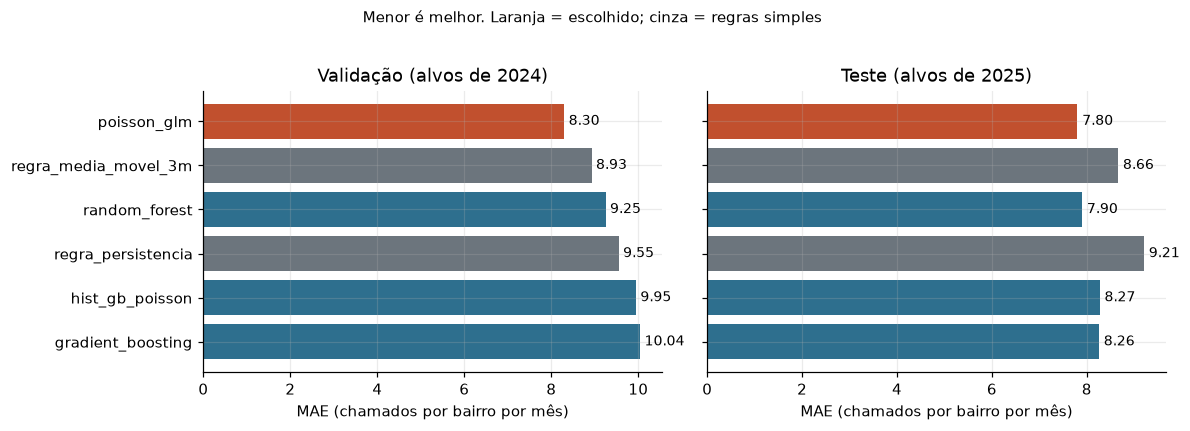

In [2]:
ordem = metricas.sort_values("val_mae").index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, coluna, titulo in zip(axes, ["val_mae", "teste_mae"], ["Validação (alvos de 2024)", "Teste (alvos de 2025)"]):
    valores = metricas.loc[ordem, coluna]
    cores = [PALETA["alerta"] if n == meta["modelo"] else PALETA["secundaria"] if n.startswith("regra_") else PALETA["primaria"] for n in ordem]
    ax.barh(ordem[::-1], valores[::-1], color=cores[::-1])
    for y, v in enumerate(valores[::-1]):
        ax.text(v + 0.1, y, f"{v:.2f}", va="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("MAE (chamados por bairro por mês)")
fig.suptitle("Menor é melhor. Laranja = escolhido; cinza = regras simples", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

**Leitura:** o `poisson_glm` é o único modelo que fica abaixo da melhor regra (`media_movel_3m`) na
validação, e também tem o menor erro no teste. Os modelos de árvore ganham da regra no teste, mas não na
validação, sinal de que dependem demais do período.

## 2. Total de chamados por mês no teste: real × previsto

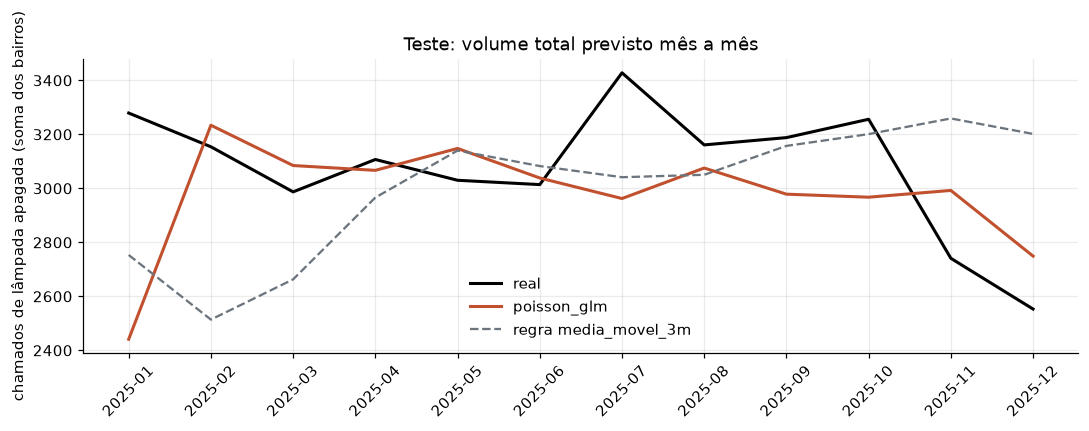

In [3]:
df = T.carregar()
treino, teste = df[df["conjunto"] == "treino"], df[df["conjunto"] == "teste"]
modelo, _ = T.candidatos()[meta["modelo"]]
modelo.fit(treino[T.FEATURES], treino[T.ALVO])
teste = teste.assign(previsto=modelo.predict(teste[T.FEATURES]))
mensal = teste.groupby("mes_do_alvo")[[T.ALVO, "previsto", "media_movel_3m"]].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mensal.index, mensal[T.ALVO], color="black", linewidth=2, label="real")
ax.plot(mensal.index, mensal["previsto"], color=PALETA["alerta"], linewidth=2, label=meta["modelo"])
ax.plot(mensal.index, mensal["media_movel_3m"], color=PALETA["secundaria"], linewidth=1.5, linestyle="--", label="regra media_movel_3m")
ax.set_ylabel("chamados de lâmpada apagada (soma dos bairros)")
ax.set_title("Teste: volume total previsto mês a mês")
ax.legend(frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. O que o modelo usa (coeficientes do GLM de Poisson)

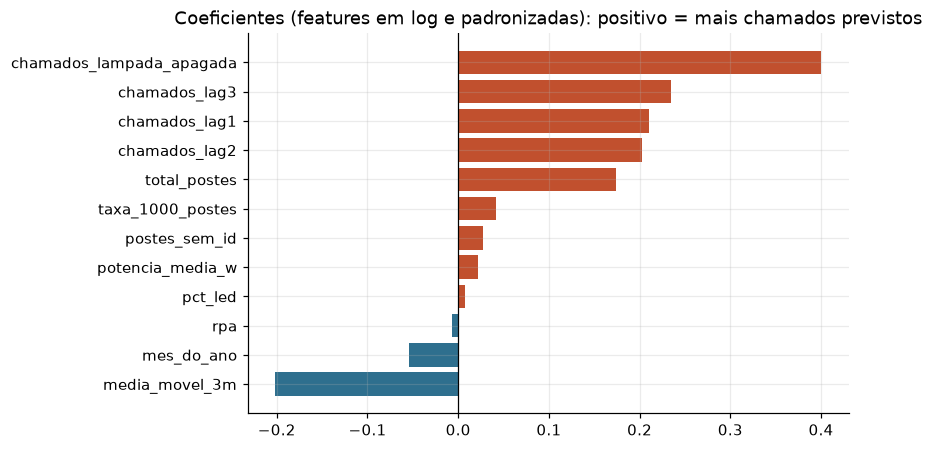

In [4]:
if meta["modelo"] == "poisson_glm":
    coef = pd.Series(modelo[-1].coef_, index=T.FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.barh(coef.index, coef.values, color=[PALETA["alerta"] if v > 0 else PALETA["primaria"] for v in coef.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title("Coeficientes (features em log e padronizadas): positivo = mais chamados previstos")
    plt.tight_layout()
    plt.show()
else:
    print("O gráfico de coeficientes só se aplica ao poisson_glm.")

**Leitura:** veja quais features puxam a previsão para cima (laranja) e para baixo (azul). Como estão em
log e padronizadas, os coeficientes podem ser comparados entre si; features muito correlacionadas entre si
(os lags e a média móvel) dividem o peso, então olhe o grupo, não cada uma sozinha.

## 4. Risco por contagem × risco por taxa (por 1.000 postes)

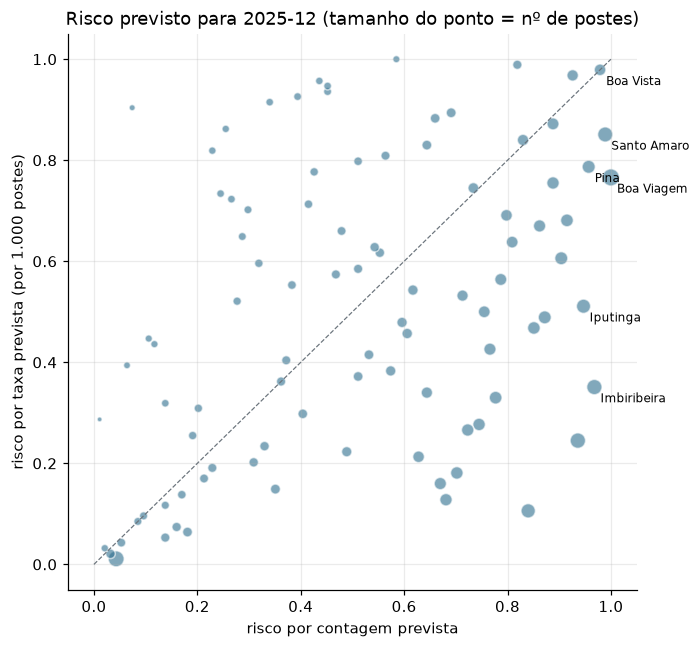

In [5]:
risco = pd.read_csv("../models/risco_por_bairro.csv")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(risco["risco_contagem"], risco["risco_taxa"], s=np.sqrt(risco["total_postes"]) * 1.5,
           color=PALETA["primaria"], alpha=0.6, edgecolor="white")
for _, r in risco.nlargest(6, "risco_contagem").iterrows():
    ax.annotate(r["bairro"].title(), (r["risco_contagem"], r["risco_taxa"]), fontsize=8,
                xytext=(4, -10), textcoords="offset points")
ax.plot([0, 1], [0, 1], color=PALETA["secundaria"], linewidth=0.8, linestyle="--")
ax.set_xlabel("risco por contagem prevista")
ax.set_ylabel("risco por taxa prevista (por 1.000 postes)")
ax.set_title(f"Risco previsto para {risco['mes_previsto'].iloc[0]} (tamanho do ponto = nº de postes)")
plt.tight_layout()
plt.show()

**Leitura:** bairros grandes (pontos maiores) ficam à direita no ranking por contagem, mas vários caem
no ranking por taxa (ex.: Várzea e Imbiribeira). Boa Vista e Recife ficam no topo dos dois: muitos chamados
**e** muitos por poste. A escolha de qual ranking vira o risco publicado está em `criterio_risco`, no
`config.json`, e é uma decisão do grupo para explicar no relatório.